# 20 · Univariate uncertainty

How much uncertainty belongs around a point forecast? Fit an AR(1), draw its future distribution, then shrink that distribution while keeping its center fixed. First inspect the points and bands; then measure what changed across independent series.

## Run this notebook

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally. The repeated comparison uses 80 series, 12 horizons, and 256 samples.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import timegym
from timegym import Scenario, GaussianAR1Forecaster
from timegym import metrics
from timegym.mutations import mutate_forecast
from timegym.diagnostics import evaluate_forecast

%matplotlib inline
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"Reference law": "#009E73", "Fitted AR(1)": "#0000CC",
          "Underdispersed AR(1)": "#D55E00"}
print(f"TimeGym {timegym.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")


TimeGym 0.2.0 | NumPy 2.5.4 | pandas 3.1.0


## Construct a forecast and a known reference

The fitted AR(1) sees only context. The reference additionally knows the generator parameters, so it is a privileged conditional law, not a learned competitor. The fitted plug-in distribution omits parameter uncertainty.

Points are `(H, 1)`, quantiles `(H, 1, Q)`, and sample paths `(S, H, 1)`. One sample contains the complete dependent future.

In [2]:
HORIZON = 12
N_SAMPLES = 256
scenario = Scenario("ar1", context_length=120, horizon=HORIZON,
                    parameters={"mean": 2.0, "phi": 0.8, "sigma": 0.8}, seed=17)
case = scenario.generate()
model = GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=2017)
model.fit(case.task.context)  # Never fit on case.observed or case.reference.
fitted = model.predict(case.task.future_index)
reference = case.reference.forecast(n_samples=N_SAMPLES, seed=1017)
shrunk = mutate_forecast(fitted, "variance_shrink")
forecasts = {"Reference law": reference, "Fitted AR(1)": fitted,
             "Underdispersed AR(1)": shrunk}

for forecast in forecasts.values():
    assert forecast.validate(case.task) == []
    assert forecast.samples.shape == (N_SAMPLES, HORIZON, 1)
display(pd.DataFrame({"point": [f.point.shape for f in forecasts.values()],
                      "quantiles": [f.quantiles.shape for f in forecasts.values()],
                      "samples": [f.samples.shape for f in forecasts.values()]},
                     index=forecasts.keys()))
display(pd.DataFrame({"estimated_intercept": model.intercept_,
                      "estimated_phi": model.phi_,
                      "estimated_innovation_variance": np.diag(model.cov_)},
                     index=case.task.target_names))


,point,quantiles,samples
Reference law,"(12, 1)","(12, 1, 3)","(256, 12, 1)"
Fitted AR(1),"(12, 1)","(12, 1, 3)","(256, 12, 1)"
Underdispersed AR(1),"(12, 1)","(12, 1, 3)","(256, 12, 1)"


,estimated_intercept,estimated_phi,estimated_innovation_variance
y,0.399734,0.757581,0.728662


## Where are the predictions, and how wide is their distribution?

Crosses mark discrete forecast points; gray dots are observations. Bands show 50% and 80% **marginal** intervals, analytically for the reference and empirically for the fitted model. Faint lines deliberately connect complete sample paths: they are possible trajectories, not connected point predictions.

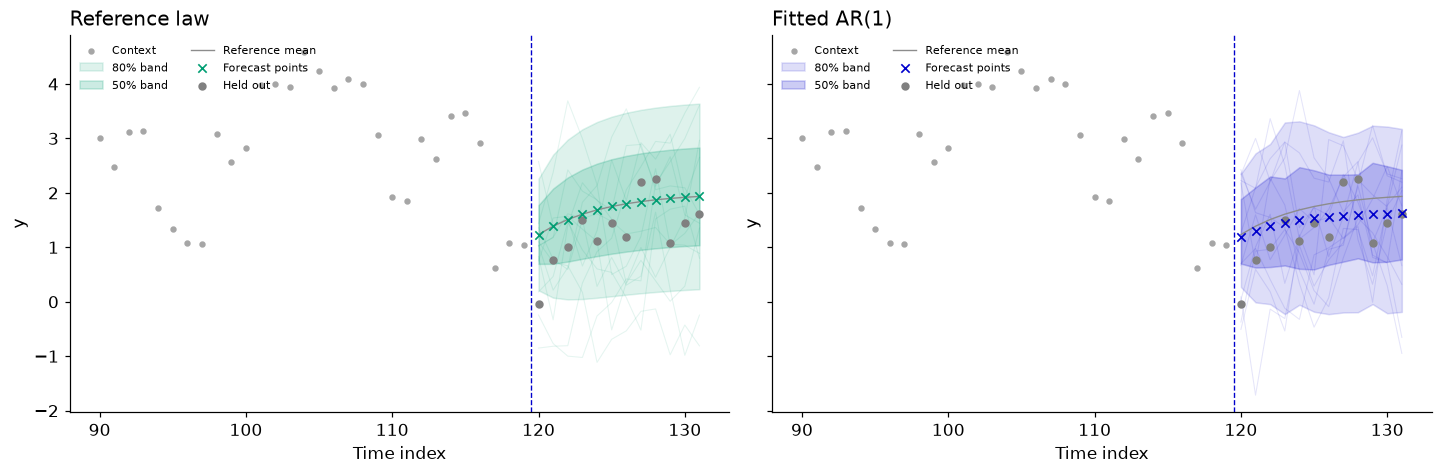

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True, sharey=True,
                         constrained_layout=True)
future = case.task.future_index.to_numpy()
context = case.task.context.iloc[-30:]
for ax, name in zip(axes, ["Reference law", "Fitted AR(1)"]):
    forecast = forecasts[name]
    bands = (case.reference.quantile((0.1, 0.25, 0.75, 0.9))[:, 0, :]
             if name == "Reference law" else
             np.quantile(forecast.samples[:, :, 0], [0.1, 0.25, 0.75, 0.9], axis=0).T)
    ax.scatter(context.index, context.iloc[:, 0], color="0.65", s=10, label="Context")
    for sample in forecast.samples[:12, :, 0]:
        ax.plot(future, sample, color=COLORS[name], alpha=0.10, linewidth=0.7)
    ax.fill_between(future, bands[:, 0], bands[:, 3], color=COLORS[name], alpha=0.13, label="80% band")
    ax.fill_between(future, bands[:, 1], bands[:, 2], color=COLORS[name], alpha=0.20, label="50% band")
    ax.plot(future, case.reference.mean[:, 0], color="0.55", linewidth=0.9, label="Reference mean")
    ax.scatter(future, forecast.point[:, 0], marker="x", color=COLORS[name],
               s=30, linewidths=1.1, label="Forecast points", zorder=4)
    ax.scatter(future, case.observed.iloc[:, 0], color="0.5", s=20, label="Held out", zorder=3)
    ax.axvline(future[0] - 0.5, color="#0000CC", linestyle="--", linewidth=0.9)
    ax.set(title=name, xlabel="Time index", ylabel="y")
    ax.legend(fontsize=7.5, loc="upper left", ncol=2)
plt.show()

The crosses summarize location, while the bands and paths show possible outcomes. The fitted center can differ from the privileged reference; a held-out dot outside a marginal band is not itself a software defect.

## Measure location and uncertainty separately

All scores are losses. MAE and MSE evaluate points; their expected-loss minimizers are the median and mean respectively, which coincide for a Gaussian law. Pinball loss evaluates the 10th, 50th, and 90th percentiles. CRPS averages marginal empirical-distribution scores; it does not measure temporal dependence.

We also show 80% interval coverage and width. Coverage on one dependent path is descriptive, not a calibration test.

In [4]:
def summarize_forecast(observed, forecast):
    lower = forecast.quantiles[:, :, 0]
    upper = forecast.quantiles[:, :, -1]
    return {
        "MAE": metrics.mae(observed, forecast.point),
        "MSE": metrics.mse(observed, forecast.point),
        "CRPS": metrics.crps(observed, forecast.samples),
        "Pinball": metrics.pinball(observed, forecast.quantiles, forecast.levels),
        "80% coverage": float(np.mean((observed >= lower) & (observed <= upper))),
        "Mean interval width": float(np.mean(upper - lower)),
    }

single_case = pd.DataFrame({name: summarize_forecast(case.observed.to_numpy(), forecast)
                           for name, forecast in forecasts.items()}).T
display(single_case.round(4))


,MAE,MSE,CRPS,Pinball,80% coverage,Mean interval width
Reference law,0.5298,0.3627,0.4068,0.1997,0.9167,3.1304
Fitted AR(1),0.4201,0.2813,0.4024,0.1898,0.9167,3.1666
Underdispersed AR(1),0.4201,0.2813,0.3282,0.1501,0.5000,0.7916


## Keep the point right while making uncertainty wrong

`variance_shrink` multiplies deviations from the point by 0.25, reducing variance by a factor of 0.0625. It is an injected output fault. The assertions below preserve MAE and MSE exactly; distributional scores and coverage may change, although not every individual realization must favor the original forecast.

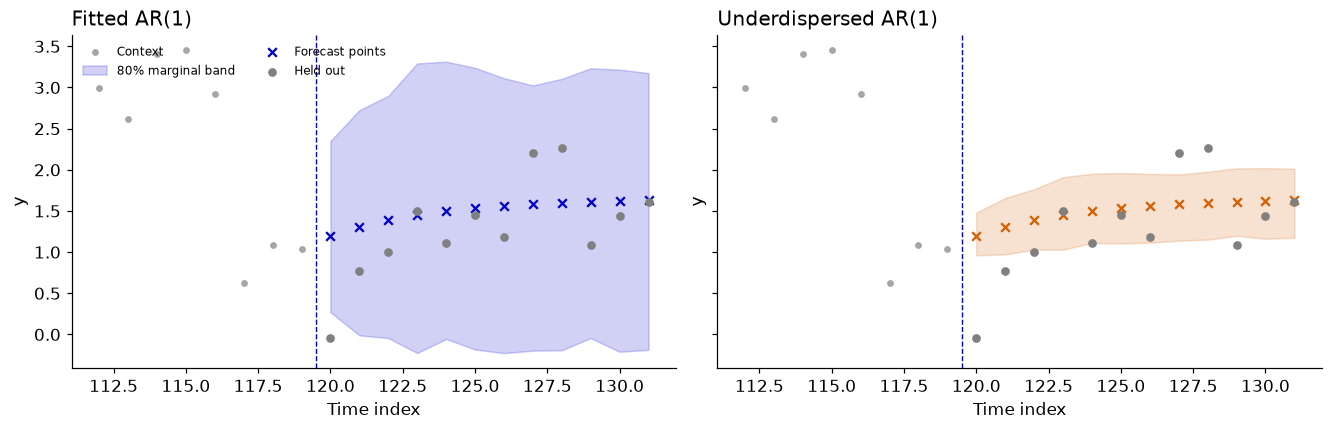

In [5]:
np.testing.assert_array_equal(fitted.point, shrunk.point)
np.testing.assert_allclose(single_case.loc["Fitted AR(1)", ["MAE", "MSE"]],
                           single_case.loc["Underdispersed AR(1)", ["MAE", "MSE"]])
np.testing.assert_allclose(shrunk.quantiles[:, :, -1] - shrunk.quantiles[:, :, 0],
                           0.25 * (fitted.quantiles[:, :, -1] - fitted.quantiles[:, :, 0]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, constrained_layout=True)
for ax, name in zip(axes, ["Fitted AR(1)", "Underdispersed AR(1)"]):
    forecast = forecasts[name]
    ax.scatter(context.index[-8:], context.iloc[-8:, 0], s=12, color="0.65", label="Context")
    ax.fill_between(future, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                    color=COLORS[name], alpha=0.18, label="80% marginal band")
    ax.scatter(future, forecast.point[:, 0], marker="x", s=32, color=COLORS[name], label="Forecast points")
    ax.scatter(future, case.observed.iloc[:, 0], s=22, color="0.5", label="Held out")
    ax.axvline(future[0] - 0.5, color="#0000CC", linestyle="--", linewidth=0.9)
    ax.set(title=name, xlabel="Time index", ylabel="y")
axes[0].legend(fontsize=8, ncol=2)
plt.show()

The forecast points stay in exactly the same locations while the orange band contracts. To see the change without a time axis, inspect one future horizon as a distribution.

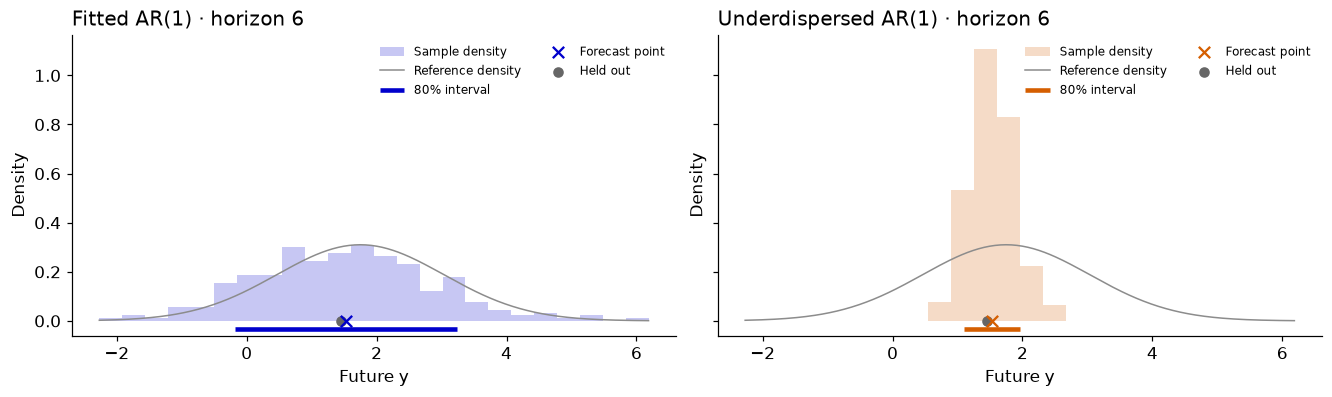

In [6]:
horizon_index = 5
names = ["Fitted AR(1)", "Underdispersed AR(1)"]
values = np.concatenate([forecasts[name].samples[:, horizon_index, 0] for name in names]
                        + [case.observed.to_numpy()[horizon_index]])
limits = (values.min() - 0.25, values.max() + 0.25)
bins = np.linspace(*limits, 25)
x = np.linspace(*limits, 300)
mu = case.reference.mean[horizon_index, 0]
sd = np.sqrt(case.reference.variance[horizon_index, 0])
reference_density = np.exp(-0.5 * ((x - mu) / sd)**2) / (sd * np.sqrt(2 * np.pi))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axes, names):
    forecast = forecasts[name]
    ax.hist(forecast.samples[:, horizon_index, 0], bins=bins, density=True,
            color=COLORS[name], alpha=0.22, label="Sample density")
    ax.plot(x, reference_density, color="0.55", linewidth=1, label="Reference density")
    interval = forecast.quantiles[horizon_index, 0, [0, -1]]
    ax.plot(interval, [-0.035, -0.035], color=COLORS[name], linewidth=3,
            solid_capstyle="butt", label="80% interval")
    ax.scatter(forecast.point[horizon_index, 0], 0, marker="x", s=55,
               color=COLORS[name], linewidths=1.5, zorder=5, label="Forecast point")
    ax.scatter(case.observed.iloc[horizon_index, 0], 0, s=35, color="0.4", zorder=4, label="Held out")
    ax.set(title=f"{name} · horizon {horizon_index + 1}", xlabel="Future y", ylabel="Density")
    ax.legend(fontsize=8, ncol=2)
axes[0].set_ylim(bottom=-0.06)
plt.show()

Both histograms have unit area and the same point prediction. The short segment below each density marks its 80% interval; it is not additional density. Shrinking concentrates mass without moving the observation, while the gray curve shows the known law. One realized observation still cannot establish calibration.

## Does the interval work across new series?

Generate 80 independent contexts and futures, refit each model, and record coverage at each horizon. Each horizon therefore has 80 independent indicators for a Wilson interval. The 12 horizons within one series are dependent; they are not 12 extra replications.

In [7]:
N_CASES = 80
seed_values = np.arange(1000, 1000 + N_CASES)
records = []
coverage_hits = {name: [] for name in forecasts}

for seed in seed_values:
    run = scenario.generate(seed=int(seed))
    fitted_run = GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=20_000 + int(seed))
    fitted_run.fit(run.task.context)
    fitted_prediction = fitted_run.predict(run.task.future_index)
    predictions = {
        "Reference law": run.reference.forecast(n_samples=N_SAMPLES, seed=10_000 + int(seed)),
        "Fitted AR(1)": fitted_prediction,
        "Underdispersed AR(1)": mutate_forecast(fitted_prediction, "variance_shrink"),
    }
    observed = run.observed.to_numpy()
    for name, prediction in predictions.items():
        records.append({"seed": int(seed), "forecast": name,
                        **summarize_forecast(observed, prediction)})
        covered = ((observed >= prediction.quantiles[:, :, 0]) &
                   (observed <= prediction.quantiles[:, :, -1]))
        coverage_hits[name].append(covered[:, 0])

per_seed = pd.DataFrame(records)
coverage_hits = {name: np.asarray(hits, dtype=bool) for name, hits in coverage_hits.items()}
assert all(hits.shape == (N_CASES, HORIZON) for hits in coverage_hits.values())
print(f"Evaluated {N_CASES} independent series × {len(forecasts)} forecasts.")


Evaluated 80 independent series × 3 forecasts.


In [8]:
def wilson_interval(successes, total, z=1.96):
    proportion = np.asarray(successes, dtype=float) / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    radius = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return center - radius, center + radius

coverage_rows = []
for name, hits in coverage_hits.items():
    lower, upper = wilson_interval(hits.sum(axis=0), N_CASES)
    for h in range(HORIZON):
        coverage_rows.append({"forecast": name, "horizon": h + 1,
                              "coverage": hits[:, h].mean(),
                              "lower_95": lower[h], "upper_95": upper[h],
                              "independent_series": N_CASES})
coverage_by_horizon = pd.DataFrame(coverage_rows)
display(coverage_by_horizon[coverage_by_horizon["horizon"].isin([1, 6, 12])]
        .round(3).reset_index(drop=True))


,forecast,horizon,coverage,lower_95,upper_95,independent_series
0,Reference law,1,0.750,0.645,0.832,80
1,Reference law,6,0.750,0.645,0.832,80
2,Reference law,12,0.750,0.645,0.832,80
3,Fitted AR(1),1,0.700,0.592,0.789,80
4,Fitted AR(1),6,0.725,0.619,0.811,80
5,Fitted AR(1),12,0.738,0.632,0.821,80
6,Underdispersed AR(1),1,0.212,0.137,0.314,80
7,Underdispersed AR(1),6,0.225,0.147,0.328,80
8,Underdispersed AR(1),12,0.262,0.179,0.368,80


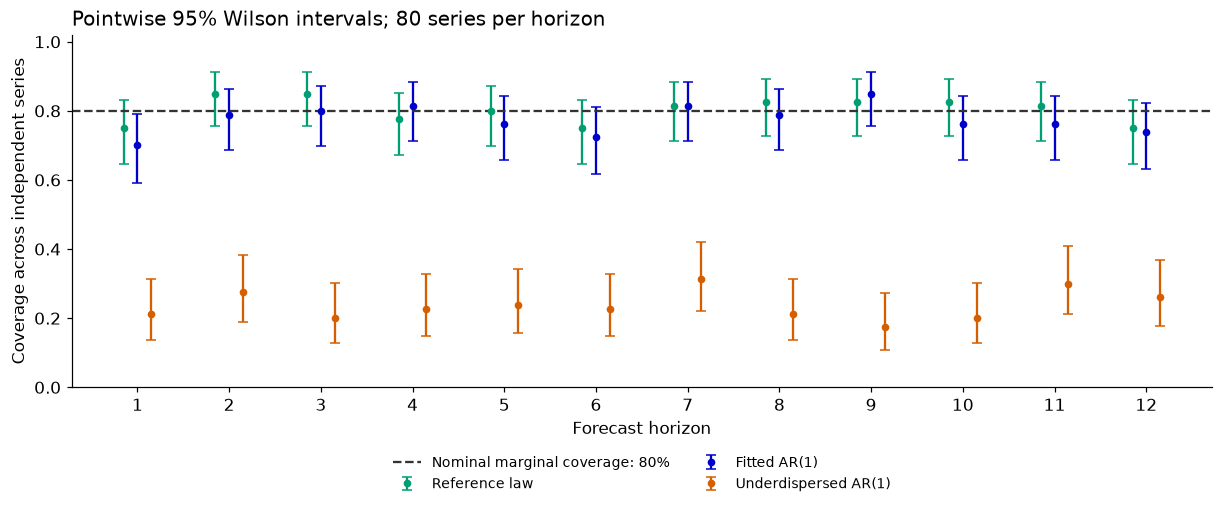

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
for offset, (name, group) in zip([-0.15, 0, 0.15], coverage_by_horizon.groupby("forecast", sort=False)):
    ax.errorbar(group["horizon"] + offset, group["coverage"],
                yerr=np.vstack([group["coverage"] - group["lower_95"],
                                group["upper_95"] - group["coverage"]]),
                fmt="o", capsize=3, markersize=4, color=COLORS[name], label=name)
ax.axhline(0.8, color="#333333", linestyle="--", label="Nominal marginal coverage: 80%")
ax.set(xlabel="Forecast horizon", ylabel="Coverage across independent series", ylim=(0, 1.02),
       xticks=np.arange(1, HORIZON + 1), title="Pointwise 95% Wilson intervals; 80 series per horizon")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.show()


The bars quantify uncertainty in **estimated coverage**, not in the next observation. These are pointwise 95% Wilson intervals, not a simultaneous band or a multiple-testing procedure. The exact reference has 80% conditional marginal coverage by construction; the fitted model has no such guarantee, and overlap with 80% does not prove calibration.

In [10]:
metric_names = ["MAE", "MSE", "CRPS", "Pinball", "80% coverage", "Mean interval width"]
summary_rows = []
for name, group in per_seed.groupby("forecast", sort=False):
    for metric in metric_names:
        values = group[metric].to_numpy()
        standard_error = values.std(ddof=1) / np.sqrt(len(values))
        summary_rows.append({"forecast": name, "metric": metric,
                             "mean": values.mean(), "seed_standard_error": standard_error,
                             "approx_lower_95": values.mean() - 1.96 * standard_error,
                             "approx_upper_95": values.mean() + 1.96 * standard_error})
seed_summary = pd.DataFrame(summary_rows)
display(seed_summary.pivot(index="metric", columns="forecast", values="mean")
        .reindex(metric_names).round(4))
display(seed_summary[seed_summary["metric"].isin(["CRPS", "80% coverage"])]
        .round(4).reset_index(drop=True))


forecast,Fitted AR(1),Reference law,Underdispersed AR(1)
metric,,,
MAE,1.0009,0.9671,1.0009
MSE,1.6196,1.4912,1.6196
CRPS,0.7180,0.6903,0.8648
Pinball,0.3192,0.3028,0.4169
80% coverage,0.7750,0.8021,0.2365
Mean interval width,2.9967,3.1304,0.7492


,forecast,metric,mean,seed_standard_error,approx_lower_95,approx_upper_95
0,Reference law,CRPS,0.6903,0.0317,0.6282,0.7525
1,Reference law,80% coverage,0.8021,0.0210,0.7609,0.8433
2,Fitted AR(1),CRPS,0.7180,0.0351,0.6492,0.7867
3,Fitted AR(1),80% coverage,0.7750,0.0222,0.7316,0.8184
4,Underdispersed AR(1),CRPS,0.8648,0.0469,0.7728,0.9569
5,Underdispersed AR(1),80% coverage,0.2365,0.0161,0.2048,0.2681


## Compare paired effects

Subtract fitted scores from shrunk scores **within each seed**, then summarize across independent series. Positive loss differences favor the original forecast; negative width differences mean narrower intervals. Mean ± 1.96 standard errors gives approximate Monte Carlo intervals without multiplicity adjustment or a pass/fail threshold.

In [11]:
paired_rows = []
for metric in metric_names:
    table = per_seed.pivot(index="seed", columns="forecast", values=metric)
    differences = table["Underdispersed AR(1)"] - table["Fitted AR(1)"]
    standard_error = differences.std(ddof=1) / np.sqrt(len(differences))
    paired_rows.append({"metric": metric, "mean_difference": differences.mean(),
                        "seed_standard_error": standard_error,
                        "approx_lower_95": differences.mean() - 1.96 * standard_error,
                        "approx_upper_95": differences.mean() + 1.96 * standard_error})
paired_summary = pd.DataFrame(paired_rows).set_index("metric")
np.testing.assert_allclose(paired_summary.loc[["MAE", "MSE"], "mean_difference"], 0.0)
display(paired_summary.round(4))


,mean_difference,seed_standard_error,approx_lower_95,approx_upper_95
metric,,,,
MAE,0.0000,0.0000,0.0000,0.0000
MSE,0.0000,0.0000,0.0000,0.0000
CRPS,0.1469,0.0130,0.1214,0.1723
Pinball,0.0977,0.0082,0.0816,0.1139
80% coverage,-0.5385,0.0182,-0.5742,-0.5028
Mean interval width,-2.2475,0.0301,-2.3065,-2.1885


## What does TimeGym conclude?

The output contract can pass while uncertainty is poor. With no declared capability tolerance, the scores remain descriptive and the capability decision is `INCONCLUSIVE`.

In [12]:
result = evaluate_forecast(case, shrunk)
display(pd.DataFrame([{"check": diagnostic.name, "status": diagnostic.status,
                       "message": diagnostic.message}
                      for diagnostic in result.diagnostics]))
assert any(d.name == "forecast_contract" and d.status == "PASS" for d in result.diagnostics)
assert any(d.name == "interval_coverage" and d.status == "INCONCLUSIVE"
           for d in result.diagnostics)


,check,status,message
0,forecast_contract,PASS,"Forecast indices, target order, shapes, finite..."
1,point_accuracy,INCONCLUSIVE,Point scores are descriptive; no capability ac...
2,quantile_accuracy,INCONCLUSIVE,Quantile loss is descriptive; no capability ac...
3,interval_coverage,INCONCLUSIVE,One-path coverage across possibly dependent co...
4,sample_scores,INCONCLUSIVE,Empirical marginal and joint scores are descri...


## Change one thing

- Reduce context length to 20, then increase it to 500: separate parameter estimation from innovation noise.
- Increase `N_SAMPLES` to examine finite-ensemble quantile noise.
- Change `phi` or `sigma`, retaining one independent series as the replication unit.
- Substitute your model's `fit(context)` and `predict(future_index)` while preserving `(S, H, D)` paths.

**Scope.** Marginal 80% bands do not give 80% simultaneous path coverage. Empirical CRPS includes diagonal sample pairs, so it is not the fair-ensemble estimator. These results concern this generator and fitting procedure, not universal calibration or real-data transfer.

Continue with [multivariate uncertainty](22_multivariate_uncertainty.ipynb). Reading: [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437).